# IMU Activity Classification — Revised Analysis

**Goal:** Build and evaluate a reproducible Random Forest baseline for five hip-exoskeleton activity classes: `sitting`, `standing`, `walking`, `stairs_up`, and `stairs_down`.

This notebook replaces duplicated feature-extraction and evaluation cells with one consistent pipeline. It uses **whole-trial holdouts** to reduce leakage between neighboring sensor windows. The 6-axis accelerometer + gyroscope model is the default export; 9-axis is evaluated as a comparison.

**Run all cells in order.** Place this notebook alongside the 15 `.txt` recordings (or change `DATA_DIR`). Requires `numpy`, `pandas`, `matplotlib`, `scikit-learn`, and `joblib`.

**Research caveat:** Three recordings per class are enough for an initial baseline, not proof of generalization to new users, placements, days, or environments.

## 1. Configuration and imports

In [6]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import joblib

DATA_DIR = Path.cwd()  # folder containing all 25 .txt files
OUTPUT_DIR = DATA_DIR / "imu_results"
OUTPUT_DIR.mkdir(exist_ok=True)
WINDOW_SECONDS = 0.5
MIN_WINDOW_FRACTION = 0.75  # minimum fraction of expected samples for a complete window
N_TREES = 200
RANDOM_STATE = 42
CLASSES = ["sitting", "standing", "walking", "stairs_up", "stairs_down"]
ACC_GYRO = ["ax", "ay", "az", "gx", "gy", "gz"]
MAG = ["mx", "my", "mz"]
SENSORS = ACC_GYRO + MAG
COLUMNS = ["time"] + SENSORS
TRIAL_FILES = {f"{state}{i}": f"{state}{i}.txt" for state in CLASSES for i in range(1, 6)}

def make_model():
    return RandomForestClassifier(n_estimators=N_TREES, random_state=RANDOM_STATE,
                                  class_weight="balanced", n_jobs=-1)

def trial_state(name):
    for state in CLASSES:
        if re.fullmatch(rf"{re.escape(state)}[1-5]", name):
            return state
    raise ValueError(f"Unrecognized trial name: {name}")


## 2. Load and audit raw recordings

Malformed rows are **counted and reported**, not silently ignored. Only lines with exactly 10 numeric fields are accepted. We also check timestamp order, sampling frequency, and possible duplicated recordings. 

In [7]:
def read_trial(path):
    valid = []
    malformed = []
    with path.open("r", encoding="utf-8-sig") as f:
        header = f.readline().strip().split("\t")
        if header != COLUMNS:
            raise ValueError(f"Unexpected header in {path.name}: {header}")
        for line_no, line in enumerate(f, start=2):
            fields = line.strip().split("\t")
            if len(fields) != len(COLUMNS):
                malformed.append((line_no, "field count", line.strip()[:100]))
                continue
            try:
                values = [float(x) for x in fields]
            except ValueError:
                malformed.append((line_no, "non-numeric", line.strip()[:100]))
                continue
            if not np.isfinite(values).all():
                malformed.append((line_no, "non-finite", line.strip()[:100]))
                continue
            valid.append(values)
    if not valid:
        raise ValueError(f"No valid samples: {path}")
    df = pd.DataFrame(valid, columns=COLUMNS)
    # A timestamp reset can indicate multiple recordings concatenated together.
    original_dt = np.diff(df["time"].to_numpy())
    resets = int(np.sum(original_dt <= 0))
    df["time_s"] = (df["time"] - df["time"].iloc[0]) / 1e6
    positive_dt = original_dt[original_dt > 0] / 1e6
    median_dt = float(np.median(positive_dt)) if len(positive_dt) else np.nan
    audit = {"file": path.name, "samples": len(df), "bad_rows": len(malformed),
             "timestamp_resets": resets, "duration_s": round(float(df["time_s"].iloc[-1]), 2),
             "median_hz": round(1 / median_dt, 2) if median_dt > 0 else np.nan,
             "bad_examples": malformed[:3]}
    return df, audit

trials, audits = {}, []
for name, filename in TRIAL_FILES.items():
    path = DATA_DIR / filename
    if not path.exists():
        matches = [p for p in DATA_DIR.glob("*.txt") if p.name.lower() == filename.lower()]
        if len(matches) != 1:
            raise FileNotFoundError(f"Expected {filename} in {DATA_DIR}")
        path = matches[0]
    df, audit = read_trial(path)
    trials[name] = df
    audits.append({"trial": name, "state": trial_state(name), **audit})

audit_df = pd.DataFrame(audits)
display(audit_df.drop(columns="bad_examples"))
print("Total malformed rows:", audit_df.bad_rows.sum())
for _, item in audit_df[audit_df.bad_rows > 0].iterrows():
    print(item.trial, "bad row examples:", item.bad_examples)
if (audit_df.timestamp_resets > 0).any():
    warnings.warn("Some trials have non-increasing timestamps. Inspect these before interpreting results.")
# Exact duplicates across entire recordings can make holdout validation optimistic.
for i, a in enumerate(trials):
    for other in list(trials)[i+1:]:
        if trials[a][SENSORS].equals(trials[other][SENSORS]):
            warnings.warn(f"Identical sensor recordings: {a} and {other}")
audit_df.to_csv(OUTPUT_DIR / "data_audit.csv", index=False)


,trial,state,file,samples,bad_rows,timestamp_resets,duration_s,median_hz
0,sitting1,sitting,sitting1.txt,1622,1,0,30.52,53.58
1,sitting2,sitting,sitting2.txt,1669,1,0,31.01,54.26
2,sitting3,sitting,sitting3.txt,1674,0,0,31.06,54.34
3,sitting4,sitting,sitting4.txt,1663,0,0,30.93,54.24
4,sitting5,sitting,sitting5.txt,1668,0,0,31.00,54.23
5,standing1,standing,standing1.txt,1629,0,0,30.61,53.71
6,standing2,standing,standing2.txt,1637,0,0,30.97,53.34
7,standing3,standing,standing3.txt,1625,1,0,30.76,53.26
8,standing4,standing,standing4.txt,1616,0,0,30.63,53.22
9,standing5,standing,standing5.txt,1633,1,0,31.01,53.08


Total malformed rows: 11
sitting1 bad row examples: [(1624, 'field count', '')]
sitting2 bad row examples: [(1671, 'field count', '')]
standing3 bad row examples: [(1627, 'field count', '')]
standing5 bad row examples: [(1635, 'field count', '')]
walking2 bad row examples: [(1641, 'field count', '')]
walking5 bad row examples: [(1630, 'field count', '')]
stairs_up1 bad row examples: [(1600, 'field count', '')]
stairs_up2 bad row examples: [(1652, 'field count', '')]
stairs_up5 bad row examples: [(1648, 'field count', ''), (1649, 'field count', '')]
stairs_down5 bad row examples: [(1654, 'field count', '')]


## 3. Window segmentation and consistent feature extraction

Windows are defined by elapsed time, not by assuming a 100 Hz sampling rate. Incomplete windows and windows with unusually few samples are excluded. The same population-standard-deviation (`ddof=0`) convention is used everywhere.

In [8]:
def extract_window_features(recordings, window_seconds=WINDOW_SECONDS):
    rows = []
    for name, data in recordings.items():
        if (data["time"].diff().iloc[1:] <= 0).any():
            warnings.warn(f"Skipping {name}: timestamps not strictly increasing")
            continue
        time_s = data["time_s"].to_numpy()
        dt = np.diff(time_s)
        expected = window_seconds / np.median(dt[dt > 0])
        n_windows = int(np.floor(time_s[-1] / window_seconds))
        for k in range(n_windows):
            segment = data.loc[(data.time_s >= k * window_seconds) &
                               (data.time_s < (k + 1) * window_seconds)]
            if len(segment) < max(2, int(np.floor(MIN_WINDOW_FRACTION * expected))):
                continue
            row = {"trial": name, "window": k, "start_s": k * window_seconds,
                   "state": trial_state(name), "n_samples": len(segment)}
            for axis in SENSORS:
                values = segment[axis].to_numpy(dtype=float)
                row[f"{axis}_mean"] = float(np.mean(values))
                row[f"{axis}_std"] = float(np.std(values, ddof=0))
                row[f"{axis}_rms"] = float(np.sqrt(np.mean(values**2)))
            rows.append(row)
    if not rows:
        raise ValueError("No valid windows produced. Check timestamps and window size.")
    return pd.DataFrame(rows)

feature_df = extract_window_features(trials)
FEATURE_9 = [f"{s}_{stat}" for s in SENSORS for stat in ("mean", "std", "rms")]
FEATURE_6 = [f"{s}_{stat}" for s in ACC_GYRO for stat in ("mean", "std", "rms")]
assert not feature_df[FEATURE_9].isna().any().any()
print("Window-level dataset:", feature_df.shape)
print("Windows per activity:\n", feature_df.groupby("state").size().to_string())
print("Windows per trial:\n", feature_df.groupby("trial").size().to_string())
feature_df.to_csv(OUTPUT_DIR / "window_features.csv", index=False)


Window-level dataset: (1530, 32)
Windows per activity:
 state
sitting        308
stairs_down    306
stairs_up      305
standing       306
walking        305
Windows per trial:
 trial
sitting1        61
sitting2        62
sitting3        62
sitting4        61
sitting5        62
stairs_down1    60
stairs_down2    61
stairs_down3    61
stairs_down4    62
stairs_down5    62
stairs_up1      60
stairs_up2      61
stairs_up3      61
stairs_up4      61
stairs_up5      62
standing1       61
standing2       61
standing3       61
standing4       61
standing5       62
walking1        61
walking2        61
walking3        61
walking4        61
walking5        61


In [9]:

# Select one recorded IMU window
test_window = feature_df.iloc[[0]]

# Load the same saved model used for Arduino export
import joblib

saved_data = joblib.load(
    "imu_results/exoskeleton_activity_model_05s_5trials.joblib"
)

rf_model = saved_data["model"]
feature_names = saved_data["features"]

# Predict using the exact saved feature order
X_test = test_window[feature_names]

prediction = rf_model.predict(X_test)[0]
probabilities = rf_model.predict_proba(X_test)[0]

print("Actual activity:", test_window["state"].iloc[0])
print("Python prediction:", prediction)
print("Predicted class index:",
      list(rf_model.classes_).index(prediction))
print("Python probabilities:", probabilities)

print("\n27 features:")
for name, value in zip(feature_names, X_test.iloc[0]):
    print(f"{name}: {value:.9g}")


Actual activity: sitting
Python prediction: sitting
Predicted class index: 0
Python probabilities: [1. 0. 0. 0. 0.]

27 features:
ax_mean: -0.12462963
ax_std: 0.00775145457
ax_rms: 0.124870451
ay_mean: 0.0508148148
ay_std: 0.00764991908
ay_rms: 0.0513874174
az_mean: 0.992037037
az_std: 0.00776736516
az_rms: 0.992067445
gx_mean: 0.0654814815
gx_std: 3.4081056
gx_rms: 3.40873461
gy_mean: -0.250962963
gy_std: 1.59126194
gy_rms: 1.61093046
gz_mean: 0.0158888889
gz_std: 1.08064001
gz_rms: 1.08075682
mx_mean: 7
mx_std: 1.36082763
mx_rms: 7.13104844
my_mean: -13.6666667
my_std: 0.902670934
my_rms: 13.6964445
mz_mean: 7.66666667
mz_std: 2
mz_rms: 7.92324288


## 4. Leave-one-trial-out baseline

For each fold, the model trains on 14 trials and predicts the held-out 15th trial. Every window receives exactly one out-of-trial prediction. **No windows from the held-out trial are used in fitting.**

Leave-one-trial-out accuracy: 0.9810

Classification report:
               precision    recall  f1-score   support

     sitting       1.00      1.00      1.00       308
    standing       1.00      0.99      0.99       306
     walking       0.99      1.00      0.99       305
   stairs_up       0.97      0.95      0.96       305
 stairs_down       0.95      0.97      0.96       306

    accuracy                           0.98      1530
   macro avg       0.98      0.98      0.98      1530
weighted avg       0.98      0.98      0.98      1530


Per-trial results:


,trial,state,windows,accuracy
0,sitting1,sitting,61,1.000000
1,sitting2,sitting,62,1.000000
2,sitting3,sitting,62,1.000000
3,sitting4,sitting,61,1.000000
4,sitting5,sitting,62,1.000000
5,stairs_down1,stairs_down,60,0.933333
6,stairs_down2,stairs_down,61,0.967213
7,stairs_down3,stairs_down,61,1.000000
8,stairs_down4,stairs_down,62,1.000000
9,stairs_down5,stairs_down,62,0.935484


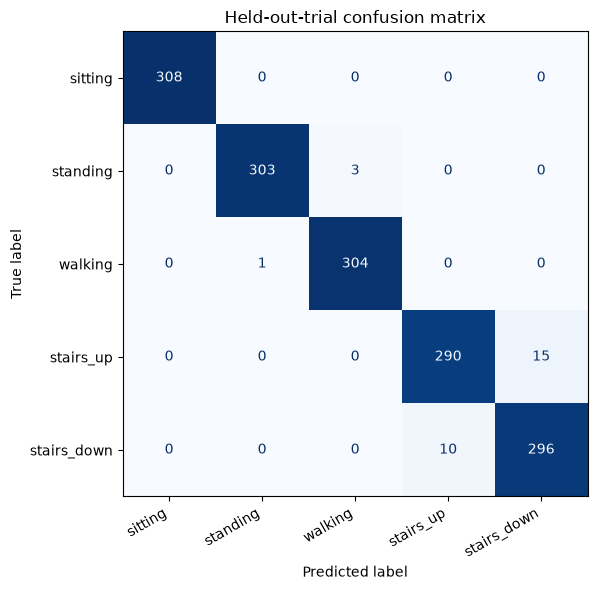

In [10]:
def evaluate_logo(frame, feature_names, verbose=True):
    X = frame[feature_names]
    y = frame["state"]
    groups = frame["trial"]
    predicted = pd.Series(index=frame.index, dtype=object)
    folds = []
    for train_idx, test_idx in LeaveOneGroupOut().split(X, y, groups):
        model = make_model()
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        p = model.predict(X.iloc[test_idx])
        predicted.iloc[test_idx] = p
        folds.append({"trial": groups.iloc[test_idx].iloc[0],
                      "state": y.iloc[test_idx].iloc[0],
                      "windows": len(test_idx),
                      "accuracy": accuracy_score(y.iloc[test_idx], p)})
    if predicted.isna().any():
        raise AssertionError("Some windows did not receive a held-out prediction")
    predictions = frame[["trial", "window", "start_s", "state"]].copy()
    predictions["prediction"] = predicted.to_numpy()
    predictions["correct"] = predictions.state == predictions.prediction
    score = accuracy_score(y, predicted)
    if verbose:
        print(f"Leave-one-trial-out accuracy: {score:.4f}")
        print("\nClassification report:\n", classification_report(y, predicted, labels=CLASSES, zero_division=0))
        print("\nPer-trial results:")
        display(pd.DataFrame(folds).sort_values("trial"))
        cm = confusion_matrix(y, predicted, labels=CLASSES)
        fig, ax = plt.subplots(figsize=(8, 6))
        ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
        plt.xticks(rotation=30, ha="right")
        plt.title("Held-out-trial confusion matrix")
        plt.tight_layout()
        plt.show()
    return {"accuracy": score, "predictions": predictions, "folds": pd.DataFrame(folds)}

# Baseline choice: 6-axis features, matching the original export intent.
baseline = evaluate_logo(feature_df, FEATURE_6)
baseline["predictions"].to_csv(OUTPUT_DIR / "baseline_predictions.csv", index=False)
baseline["folds"].to_csv(OUTPUT_DIR / "baseline_trial_scores.csv", index=False)


## 5. Error analysis

Identify activity confusions and the individual trials where predictions fail. These results can guide new data collection, particularly around walking and stair transitions.

In [11]:
errors = baseline["predictions"].loc[lambda d: ~d.correct].copy()
print("Total misclassified windows:", len(errors))
print("\nErrors by true / predicted class:")
display(pd.crosstab(errors.state, errors.prediction))
print("\nWorst held-out trials:")
display(baseline["folds"].sort_values("accuracy").head(10))
print("\nFirst misclassified windows (seconds from trial start):")
display(errors.head(20))


Total misclassified windows: 29

Errors by true / predicted class:


prediction,stairs_down,stairs_up,standing,walking
state,,,,
stairs_down,0,10,0,0
stairs_up,15,0,0,0
standing,0,0,0,3
walking,0,0,1,0



Worst held-out trials:


,trial,state,windows,accuracy
11,stairs_up2,stairs_up,61,0.918033
14,stairs_up5,stairs_up,62,0.919355
5,stairs_down1,stairs_down,60,0.933333
10,stairs_up1,stairs_up,60,0.933333
9,stairs_down5,stairs_down,62,0.935484
6,stairs_down2,stairs_down,61,0.967213
15,standing1,standing,61,0.967213
12,stairs_up3,stairs_up,61,0.983607
21,walking2,walking,61,0.983607
19,standing5,standing,62,0.983871



First misclassified windows (seconds from trial start):


,trial,window,start_s,state,prediction,correct
315,standing1,7,3.5,standing,walking,False
316,standing1,8,4.0,standing,walking,False
556,standing5,4,2.0,standing,walking,False
735,walking2,60,30.0,walking,standing,False
923,stairs_up1,4,2.0,stairs_up,stairs_down,False
928,stairs_up1,9,4.5,stairs_up,stairs_down,False
946,stairs_up1,27,13.5,stairs_up,stairs_down,False
953,stairs_up1,34,17.0,stairs_up,stairs_down,False
981,stairs_up2,2,1.0,stairs_up,stairs_down,False
984,stairs_up2,5,2.5,stairs_up,stairs_down,False


## 6. Sensor and feature analysis

Compare window-level features by activity, and inspect feature importance from a separately trained model on the entire current dataset. Feature importance is **descriptive**, not a held-out validation result.

,ax_mean,ax_std,ax_rms,ay_mean,ay_std,ay_rms,az_mean,az_std,az_rms,gx_mean,gx_std,gx_rms,gy_mean,gy_std,gy_rms,gz_mean,gz_std,gz_rms
state,,,,,,,,,,,,,,,,,,
sitting,0.151,0.006,0.193,0.073,0.008,0.077,0.970,0.008,0.970,0.176,3.423,3.695,0.039,1.482,1.661,-0.034,1.241,1.438
stairs_down,-0.773,0.209,0.803,0.472,0.184,0.510,0.391,0.151,0.424,12.682,48.716,60.648,-6.650,31.421,38.432,-8.938,22.425,28.663
stairs_up,-0.749,0.182,0.774,0.406,0.156,0.446,0.432,0.174,0.469,-14.786,48.968,67.983,9.561,35.973,55.067,6.342,18.124,24.935
standing,0.962,0.004,0.962,0.151,0.006,0.151,-0.151,0.008,0.156,0.116,5.001,5.402,0.066,2.670,2.956,-0.111,1.006,1.132
walking,0.957,0.114,0.965,0.081,0.075,0.146,0.126,0.128,0.215,12.494,44.169,64.049,0.110,32.236,45.864,0.097,16.466,19.968


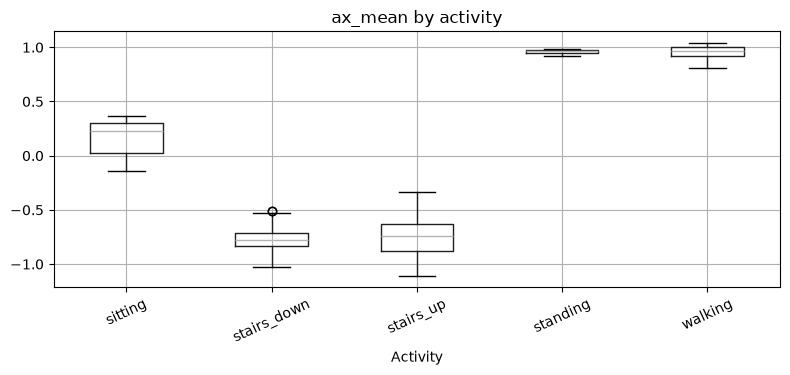

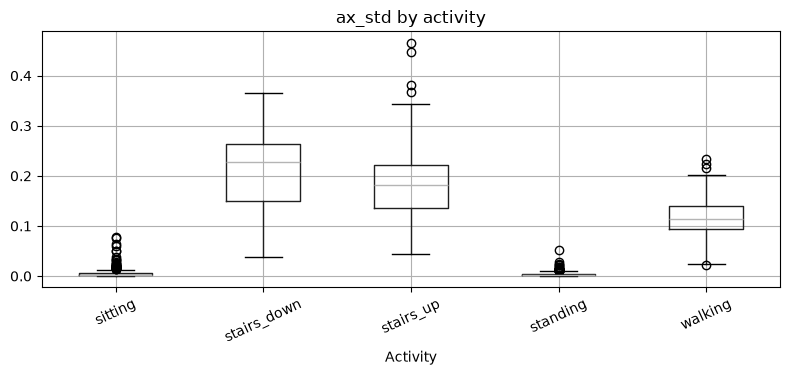

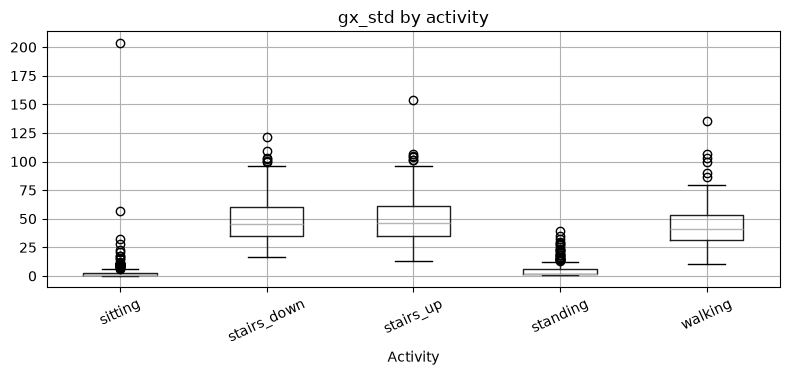

,feature,importance
0,ax_mean,0.183445
6,az_mean,0.108743
2,ax_rms,0.083341
8,az_rms,0.081612
4,ay_std,0.080409
1,ax_std,0.068186
14,gy_rms,0.067651
5,ay_rms,0.047862
17,gz_rms,0.044577
7,az_std,0.033518


In [12]:
state_means = feature_df.groupby("state")[FEATURE_6].mean()
display(state_means.round(3))
for f in ["ax_mean", "ax_std", "gx_std"]:
    fig, ax = plt.subplots(figsize=(8, 4))
    feature_df.boxplot(column=f, by="state", ax=ax)
    ax.set_title(f"{f} by activity")
    ax.set_xlabel("Activity")
    plt.suptitle("")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

interpretation_model = make_model()
interpretation_model.fit(feature_df[FEATURE_6], feature_df.state)
importance = pd.DataFrame({"feature": FEATURE_6, "importance": interpretation_model.feature_importances_})
importance = importance.sort_values("importance", ascending=False)
display(importance)
importance.to_csv(OUTPUT_DIR / "feature_importance.csv", index=False)


## 7. Controlled experiment: 6-axis vs. 9-axis

Use exactly the same windows, model settings, and held-out trials. A higher score here does not by itself establish that the magnetometer is robust to a different environment.

In [13]:
comparison = []
for label, cols in [("6-axis", FEATURE_6), ("9-axis", FEATURE_9)]:
    result = evaluate_logo(feature_df, cols, verbose=False)
    comparison.append({"feature_set": label, "features": len(cols),
                       "windows": len(feature_df), "logo_accuracy": result["accuracy"]})
comparison_df = pd.DataFrame(comparison)
display(comparison_df)
comparison_df.to_csv(OUTPUT_DIR / "sensor_comparison.csv", index=False)


,feature_set,features,windows,logo_accuracy
0,6-axis,18,1530,0.981046
1,9-axis,27,1530,0.981699


## 8. Optional experiment: window duration

Compare 0.5, 1.0, and 2.0 second windows. The resulting datasets have different numbers of windows; compare both accuracy and latency implications. Longer windows may be easier to classify but slower to respond to activity changes.

In [14]:
window_experiments = []
for seconds in [0.5, 1.0, 2.0]:
    candidate = extract_window_features(trials, seconds)
    result = evaluate_logo(candidate, FEATURE_6, verbose=False)
    window_experiments.append({"window_s": seconds, "windows": len(candidate),
                               "logo_accuracy": result["accuracy"]})
window_comparison = pd.DataFrame(window_experiments)
display(window_comparison)
window_comparison.to_csv(OUTPUT_DIR / "window_comparison.csv", index=False)


,window_s,windows,logo_accuracy
0,0.5,1530,0.981046
1,1.0,757,0.986790
2,2.0,375,0.986667


## 9. Train and export the baseline

Train on **all available windows only after reporting the held-out-trial evaluation**. This exported model has no untouched final test set; it is a baseline for offline/inference testing, not a validated control system. Metadata records the exact feature order, window duration, and extraction conventions.

In [15]:
# Train the final 9-axis classifier on all available windows.
final_model = make_model()
final_model.fit(feature_df[FEATURE_9], feature_df.state)

# Reuse the 9-axis held-out-trial evaluation from Section 7.
nine_axis_accuracy = float(
    comparison_df.loc[comparison_df["feature_set"] == "9-axis", "logo_accuracy"].iloc[0]
)

artifact = {
    "model": final_model,
    "features": FEATURE_9,
    "classes": final_model.classes_.tolist(),
    "window_seconds": WINDOW_SECONDS,
    "sensors": SENSORS,
    "feature_statistics": ["mean", "std_ddof0", "rms"],
    "min_window_fraction": MIN_WINDOW_FRACTION,
    "sampling": "time-based windows using microsecond timestamps",
    "validation": "LeaveOneGroupOut by complete recording",
    "held_out_trial_accuracy": nine_axis_accuracy,
}

model_path = OUTPUT_DIR / "exoskeleton_activity_model_05s_5trials.joblib"
joblib.dump(artifact, model_path)

# Verify the exported file can be loaded and contains all 27 features.
loaded = joblib.load(model_path)
assert len(loaded["features"]) == 27
assert loaded["model"].n_features_in_ == 27
print("Model saved and loaded successfully:", model_path)
print("Number of features:", len(loaded["features"]))
print("Activities:", loaded["classes"])
print("9-axis held-out-trial accuracy (before final refit):", round(nine_axis_accuracy, 4))


Model saved and loaded successfully: c:\Users\akals\OneDrive\Desktop\Lab\IMU_Analysis\imu_results\exoskeleton_activity_model_05s_5trials.joblib
Number of features: 27
Activities: ['sitting', 'stairs_down', 'stairs_up', 'standing', 'walking']
9-axis held-out-trial accuracy (before final refit): 0.9817


Live Classifier Implentation for Arduino Nano

In [26]:

import joblib
from pathlib import Path

# Load the trained 0.5-second, five-trial model
model_path = Path("imu_results/exoskeleton_activity_model_05s_5trials.joblib")

saved_data = joblib.load(model_path)

# Extract the classifier and feature names
rf_model = saved_data["model"]
feature_names = saved_data["features"]

print("Number of trees:", len(rf_model.estimators_))
print("Number of features:", len(feature_names))
print("Activity classes:", rf_model.classes_)

print("\nFeatures in order:")
for i, feature in enumerate(feature_names):
    print(f"{i + 1}. {feature}")


Number of trees: 200
Number of features: 27
Activity classes: ['sitting' 'stairs_down' 'stairs_up' 'standing' 'walking']

Features in order:
1. ax_mean
2. ax_std
3. ax_rms
4. ay_mean
5. ay_std
6. ay_rms
7. az_mean
8. az_std
9. az_rms
10. gx_mean
11. gx_std
12. gx_rms
13. gy_mean
14. gy_std
15. gy_rms
16. gz_mean
17. gz_std
18. gz_rms
19. mx_mean
20. mx_std
21. mx_rms
22. my_mean
23. my_std
24. my_rms
25. mz_mean
26. mz_std
27. mz_rms


In [17]:

import numpy as np

# Examine the structure of the trained Random Forest
node_counts = [
    tree.tree_.node_count
    for tree in rf_model.estimators_
]

tree_depths = [
    tree.tree_.max_depth
    for tree in rf_model.estimators_
]

total_nodes = sum(node_counts)

print("RANDOM FOREST STRUCTURE")
print("-----------------------")
print("Number of trees:", len(rf_model.estimators_))
print("Total decision nodes:", total_nodes)
print("Average nodes per tree:", round(np.mean(node_counts), 2))
print("Maximum tree depth:", max(tree_depths))

# Estimate memory for compact C/C++ representations
print("\nESTIMATED MODEL STORAGE")
print("-----------------------")

for bytes_per_node in [12, 16, 20]:
    estimated_kb = total_nodes * bytes_per_node / 1024
    print(f"{bytes_per_node} bytes/node: {estimated_kb:.2f} KB")

print("\nARDUINO NANO 33 BLE SENSE REV2")
print("-----------------------------")
print("Flash memory: 1024 KB")
print("RAM: 256 KB")


RANDOM FOREST STRUCTURE
-----------------------
Number of trees: 200
Total decision nodes: 20678
Average nodes per tree: 103.39
Maximum tree depth: 20

ESTIMATED MODEL STORAGE
-----------------------
12 bytes/node: 242.32 KB
16 bytes/node: 323.09 KB
20 bytes/node: 403.87 KB

ARDUINO NANO 33 BLE SENSE REV2
-----------------------------
Flash memory: 1024 KB
RAM: 256 KB


In [18]:

import numpy as np
from pathlib import Path

output_dir = Path("imu_results/embedded")
output_dir.mkdir(parents=True, exist_ok=True)

header_path = output_dir / "random_forest_model.h"

# Export the model's decision nodes as C++ data.
# This is a first-pass representation for size testing.

with open(header_path, "w") as f:
    f.write("#pragma once\n")
    f.write("#include <stdint.h>\n\n")

    f.write("struct RFNode {\n")
    f.write("  int16_t feature;\n")
    f.write("  int16_t left;\n")
    f.write("  int16_t right;\n")
    f.write("  float threshold;\n")
    f.write("};\n\n")

    for tree_idx, estimator in enumerate(rf_model.estimators_):
        tree = estimator.tree_

        f.write(f"const RFNode tree_{tree_idx}[] = {{\n")

        for node_idx in range(tree.node_count):
            feature = int(tree.feature[node_idx])
            left = int(tree.children_left[node_idx])
            right = int(tree.children_right[node_idx])
            threshold = float(tree.threshold[node_idx])

            # Leaf nodes have feature = -2 and children = -1.
            # Leaf class outputs will be exported separately.
            f.write(
                f"  {{{feature}, {left}, {right}, "
                f"{threshold:.9g}f}},\n"
            )

        f.write("};\n\n")

print("Exported:", header_path)
print("Header size:", round(header_path.stat().st_size / 1024, 2), "KB")


Exported: imu_results\embedded\random_forest_model.h
Header size: 531.43 KB


In [19]:

import numpy as np

total_leaves = 0
total_internal_nodes = 0

for estimator in rf_model.estimators_:
    tree = estimator.tree_

    is_leaf = tree.children_left == -1

    total_leaves += np.sum(is_leaf)
    total_internal_nodes += np.sum(~is_leaf)

print("RANDOM FOREST NODE BREAKDOWN")
print("----------------------------")
print("Total nodes:", total_leaves + total_internal_nodes)
print("Internal decision nodes:", total_internal_nodes)
print("Leaf nodes:", total_leaves)

print("\nESTIMATED LEAF STORAGE")
print("----------------------")

# Five float32 class probabilities per leaf
leaf_storage = total_leaves * 5 * 4

print("Leaf probability storage:",
      round(leaf_storage / 1024, 2), "KB")

print("\nESTIMATED TOTAL MODEL STORAGE")
print("-----------------------------")

# Preliminary estimate: 12 bytes per node plus leaf probabilities
node_storage = (total_leaves + total_internal_nodes) * 12

total_storage = node_storage + leaf_storage

print("Decision-node storage:",
      round(node_storage / 1024, 2), "KB")

print("Leaf probability storage:",
      round(leaf_storage / 1024, 2), "KB")

print("Combined estimate:",
      round(total_storage / 1024, 2), "KB")


RANDOM FOREST NODE BREAKDOWN
----------------------------
Total nodes: 20678
Internal decision nodes: 10239
Leaf nodes: 10439

ESTIMATED LEAF STORAGE
----------------------
Leaf probability storage: 203.89 KB

ESTIMATED TOTAL MODEL STORAGE
-----------------------------
Decision-node storage: 242.32 KB
Leaf probability storage: 203.89 KB
Combined estimate: 446.21 KB


In [20]:

import numpy as np

total_leaves = 0
pure_leaves = 0
mixed_leaves = 0
max_nonzero_classes = 0

for estimator in rf_model.estimators_:
    tree = estimator.tree_

    for node_idx in range(tree.node_count):
        if tree.children_left[node_idx] == -1:

            total_leaves += 1

            # Class values stored at this leaf
            values = tree.value[node_idx][0]

            nonzero_classes = np.count_nonzero(values > 0)

            max_nonzero_classes = max(
                max_nonzero_classes,
                nonzero_classes
            )

            if nonzero_classes == 1:
                pure_leaves += 1
            else:
                mixed_leaves += 1

print("LEAF PURITY ANALYSIS")
print("--------------------")
print("Total leaves:", total_leaves)
print("Pure leaves:", pure_leaves)
print("Mixed leaves:", mixed_leaves)

print("\nPercentage of pure leaves:",
      round(100 * pure_leaves / total_leaves, 2), "%")

print("Maximum nonzero classes in a leaf:",
      max_nonzero_classes)


LEAF PURITY ANALYSIS
--------------------
Total leaves: 10439
Pure leaves: 10439
Mixed leaves: 0

Percentage of pure leaves: 100.0 %
Maximum nonzero classes in a leaf: 1


In [21]:

import joblib
from pathlib import Path

# Load the previously trained Random Forest model
model_path = Path("imu_results/exoskeleton_activity_model_05s_5trials.joblib")

saved_data = joblib.load(model_path)

rf_model = saved_data["model"]
feature_names = saved_data["features"]

print("Model loaded successfully!")
print("Number of trees:", len(rf_model.estimators_))
print("Number of features:", len(feature_names))
print("Classes:", rf_model.classes_)


Model loaded successfully!
Number of trees: 200
Number of features: 27
Classes: ['sitting' 'stairs_down' 'stairs_up' 'standing' 'walking']


In [22]:

from pathlib import Path
import numpy as np

output_dir = Path("imu_results/embedded")
output_dir.mkdir(parents=True, exist_ok=True)

header_path = output_dir / "random_forest_compact.h"

# Format every threshold as a valid C++ float literal.
def cpp_float(value):
    text = format(float(value), ".9g")

    # Integers such as 0, 14, -31 need a decimal point.
    if "." not in text and "e" not in text.lower():
        text += ".0"

    return text + "f"


with open(header_path, "w") as f:
    f.write("#pragma once\n")
    f.write("#include <stdint.h>\n\n")

    f.write("struct RFNode {\n")
    f.write("  float threshold;\n")
    f.write("  int16_t left;\n")
    f.write("  int16_t right;\n")
    f.write("  int8_t feature;\n")
    f.write("  uint8_t class_id;\n")
    f.write("};\n\n")

    f.write(
        f"constexpr int RF_NUM_TREES = "
        f"{len(rf_model.estimators_)};\n"
    )
    f.write(
        f"constexpr int RF_NUM_FEATURES = "
        f"{len(feature_names)};\n"
    )
    f.write(
        f"constexpr int RF_NUM_CLASSES = "
        f"{len(rf_model.classes_)};\n\n"
    )

    for tree_idx, estimator in enumerate(rf_model.estimators_):
        tree = estimator.tree_

        f.write(f"const RFNode rf_tree_{tree_idx}[] = {{\n")

        for node_idx in range(tree.node_count):
            left = int(tree.children_left[node_idx])
            right = int(tree.children_right[node_idx])

            if left == -1:
                # Leaf: store the winning class index
                feature = -1
                threshold = 0.0
                class_id = int(np.argmax(tree.value[node_idx][0]))
            else:
                feature = int(tree.feature[node_idx])
                threshold = float(tree.threshold[node_idx])
                class_id = 0

            f.write(
                f"  {{{cpp_float(threshold)}, {left}, {right}, "
                f"{feature}, {class_id}}},\n"
            )

        f.write("};\n\n")

    f.write("const RFNode* const rf_trees[] = {\n")

    for tree_idx in range(len(rf_model.estimators_)):
        f.write(f"  rf_tree_{tree_idx},\n")

    f.write("};\n")

print("Compact model exported:", header_path)
print(
    "Header size:",
    round(header_path.stat().st_size / 1024, 2),
    "KB"
)


Compact model exported: imu_results\embedded\random_forest_compact.h
Header size: 605.99 KB


In [23]:

from pathlib import Path

output_dir = Path("imu_results/embedded")
output_dir.mkdir(parents=True, exist_ok=True)

predictor_path = output_dir / "random_forest_predict.h"

predictor_code = r"""
#pragma once

#include <stdint.h>
#include "random_forest_compact.h"

// Activity class order:
// 0 = sitting
// 1 = stairs_down
// 2 = stairs_up
// 3 = standing
// 4 = walking

// Return predicted class index.
// Optionally return confidence as a value from 0.0 to 1.0.
inline uint8_t predictActivity(
    const float features[RF_NUM_FEATURES],
    float* confidence = nullptr
) {
    uint16_t votes[RF_NUM_CLASSES] = {0};

    for (int t = 0; t < RF_NUM_TREES; ++t) {
        const RFNode* tree = rf_trees[t];
        int nodeIndex = 0;

        while (tree[nodeIndex].feature >= 0) {
            const RFNode& node = tree[nodeIndex];

            if (features[node.feature] <= node.threshold) {
                nodeIndex = node.left;
            } else {
                nodeIndex = node.right;
            }
        }

        uint8_t classId = tree[nodeIndex].class_id;
        votes[classId]++;
    }

    uint8_t bestClass = 0;

    for (uint8_t c = 1; c < RF_NUM_CLASSES; ++c) {
        if (votes[c] > votes[bestClass]) {
            bestClass = c;
        }
    }

    if (confidence != nullptr) {
        *confidence =
            static_cast<float>(votes[bestClass]) / RF_NUM_TREES;
    }

    return bestClass;
}
"""

predictor_path.write_text(predictor_code, encoding="utf-8")

print("Prediction function exported:", predictor_path)
print("File size:", round(predictor_path.stat().st_size / 1024, 2), "KB")


Prediction function exported: imu_results\embedded\random_forest_predict.h
File size: 1.25 KB


In [24]:

activities = [
    "standing",
    "walking",
    "stairs_up",
    "stairs_down"
]

for activity in activities:
    window = feature_df[feature_df["state"] == activity].iloc[[0]]
    X = window[feature_names]

    prediction = rf_model.predict(X)[0]
    probabilities = rf_model.predict_proba(X)[0]

    print(f"\nActivity: {activity}")
    print(f"Python prediction: {prediction}")
    print(f"Python probability: {max(probabilities):.4f}")

    print("C++ features:")
    values = X.iloc[0].to_numpy()

    for i in range(0, len(values), 3):
        print(
            "  " +
            ", ".join(f"{v:.9g}f" if "." in f"{v:.9g}"
                      else f"{v:.9g}.0f"
                      for v in values[i:i+3]) +
            ","
        )



Activity: standing
Python prediction: standing
Python probability: 1.0000
C++ features:
  0.976444444f, 0.00355208164f, 0.976450905f,
  0.0839259259f, 0.00640558741f, 0.0841700219f,
  -0.149037037f, 0.00967425557f, 0.149350693f,
  -0.947222222f, 4.13481102f, 4.2419208f,
  -1.33155556f, 1.71807182f, 2.17366303f,
  -0.56737037f, 0.698115142f, 0.899596514f,
  -3.81481481f, 1.44111677f, 4.07794429f,
  -37.962963f, 1.73165477f, 38.0024366f,
  -19.4444444f, 1.44871165f, 19.498338f,

Activity: walking
Python prediction: walking
Python probability: 0.8650
C++ features:
  0.969888889f, 0.128648915f, 0.978383871f,
  0.0925925926f, 0.0851731392f, 0.125808791f,
  0.171296296f, 0.163072539f, 0.23650597f,
  38.6555926f, 52.2670085f, 65.0084227f,
  -40.2492963f, 41.0065655f, 57.459066f,
  22.1806667f, 16.6615296f, 27.7414589f,
  -16.9259259f, 1.41227229f, 16.9847426f,
  -14.1481481f, 1.48333218f, 14.225694f,
  -17.037037f, 0.961537406f, 17.0641491f,

Activity: stairs_up
Python prediction: stairs_up


In [25]:

import inspect

print("Feature columns:")
print(feature_names)

print("\nFeature count:", len(feature_names))

print("\nFeature values from first window:")
print(feature_df[feature_names].iloc[0])


Feature columns:
['ax_mean', 'ax_std', 'ax_rms', 'ay_mean', 'ay_std', 'ay_rms', 'az_mean', 'az_std', 'az_rms', 'gx_mean', 'gx_std', 'gx_rms', 'gy_mean', 'gy_std', 'gy_rms', 'gz_mean', 'gz_std', 'gz_rms', 'mx_mean', 'mx_std', 'mx_rms', 'my_mean', 'my_std', 'my_rms', 'mz_mean', 'mz_std', 'mz_rms']

Feature count: 27

Feature values from first window:
ax_mean    -0.124630
ax_std      0.007751
ax_rms      0.124870
ay_mean     0.050815
ay_std      0.007650
ay_rms      0.051387
az_mean     0.992037
az_std      0.007767
az_rms      0.992067
gx_mean     0.065481
gx_std      3.408106
gx_rms      3.408735
gy_mean    -0.250963
gy_std      1.591262
gy_rms      1.610930
gz_mean     0.015889
gz_std      1.080640
gz_rms      1.080757
mx_mean     7.000000
mx_std      1.360828
mx_rms      7.131048
my_mean   -13.666667
my_std      0.902671
my_rms     13.696445
mz_mean     7.666667
mz_std      2.000000
mz_rms      7.923243
Name: 0, dtype: float64
